<a href="https://colab.research.google.com/github/Soheilp86/Statistical-Machine-Learning/blob/main/52_Random_Forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/Soheilp86/Statistical-Machine-Learning/blob/main/52_Random_Forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Random Forests

In this notebook we will

1. see why a single decision tree is **unstable**,
2. learn **what** a random forest is, **why** it works, and **how** it is built,
3. apply it to the **Heart Disease** dataset and compare it with a single tree and with bagging,
4. look at the **out-of-bag (OOB)** score and **feature importance**, and
5. see where random forests are used, including **inside** other ML pipelines.

**Reference:** *An Introduction to Statistical Learning (ISLR)*, Chapter 8.2.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.inspection import permutation_importance

## The Data: Heart Disease (Cleveland)

We will use one dataset throughout the notebook. The **Cleveland Heart Disease** data (UCI) has 303 patients and 13 clinical measurements, such as age, cholesterol, maximum heart rate, and chest-pain type. The goal is to predict whether a patient has heart disease.

The original label `num` goes from 0 (no disease) to 4. As is standard, we turn it into a yes/no label: `disease = 1` if `num > 0`.

In [3]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
cols = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
        "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]

heart = pd.read_csv(url, header=None, names=cols, na_values="?")
print("Missing values per column:")
print(heart.isna().sum()[heart.isna().sum() > 0])

heart = heart.dropna()                        # only 6 rows have missing values
heart["disease"] = (heart["num"] > 0).astype(int)

X = heart.drop(columns=["num", "disease"])
y = heart["disease"]

print(f"\nShape: {X.shape}")
print("Class balance:", y.value_counts().to_dict())
heart.head()

Missing values per column:
ca      4
thal    2
dtype: int64

Shape: (297, 13)
Class balance: {0: 160, 1: 137}


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,disease
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,0


| Feature | Meaning |
|---|---|
| `age`, `sex` | age in years, sex (1 = male) |
| `cp` | chest-pain type (1–4) |
| `trestbps` | resting blood pressure |
| `chol` | serum cholesterol |
| `fbs` | fasting blood sugar > 120 mg/dl |
| `restecg` | resting ECG result |
| `thalach` | maximum heart rate achieved |
| `exang` | exercise-induced angina |
| `oldpeak`, `slope` | ST depression and slope during exercise |
| `ca` | number of major vessels colored by fluoroscopy (0–3) |
| `thal` | thallium stress test result (3, 6, 7) |

Some features (`cp`, `thal`, `restecg`) are categories stored as numbers. Trees can split on them directly, so we leave them as they are.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print(f"Train: {len(X_train)} patients   Test: {len(X_test)} patients")

Train: 222 patients   Test: 75 patients


## Motivation: A Single Tree Is Unstable

In the decision trees notebook we saw that a deep tree can fit the training data perfectly. The problem is that it is **unstable**: train it on a slightly different sample of patients and you can get a very different tree.

Let's check. We draw three **bootstrap samples** of the training set (sample the same number of rows *with replacement*), grow a deep tree on each, and look at the first question (root split) each tree asks.

In [6]:
rng = np.random.RandomState(0)
trees = []

for i in range(3):
    idx = rng.choice(len(X_train), size=len(X_train), replace=True)
    t = DecisionTreeClassifier(random_state=0).fit(X_train.iloc[idx], y_train.iloc[idx])
    trees.append(t)

    root_feature = X.columns[t.tree_.feature[0]]
    root_threshold = t.tree_.threshold[0]
    print(f"Tree {i+1}: root split = {root_feature} <= {root_threshold:.1f},  "
          f"depth = {t.get_depth()},  test accuracy = {t.score(X_test, y_test):.3f}")

# How often do two trees disagree on the same test patient?
p1, p2 = trees[0].predict(X_test), trees[1].predict(X_test)
print(f"\nTree 1 and Tree 2 disagree on {np.mean(p1 != p2):.0%} of test patients.")

Tree 1: root split = cp <= 3.5,  depth = 7,  test accuracy = 0.707
Tree 2: root split = thal <= 6.5,  depth = 7,  test accuracy = 0.707
Tree 3: root split = cp <= 3.5,  depth = 8,  test accuracy = 0.747

Tree 1 and Tree 2 disagree on 21% of test patients.


Small changes in the data give different trees, different accuracies, and different predictions for the same patient. In statistical terms, a deep tree has **low bias but high variance**.

The idea of a random forest: if one tree is noisy, **grow many trees and average them**.

## The Algorithm: What, Why, How?

**What is a Random Forest?**

A random forest is a collection (ensemble) of many decision trees. For **classification** the forest predicts by **majority vote** of the trees. For **regression** it predicts the **average** of the trees.

*Example:* 500 trees look at a new patient. 340 trees say "disease" and 160 say "no disease". The forest predicts **disease**, with 68% of the votes.

**Why does it work?**

**Problem 1: one tree has high variance.** Averaging many models reduces variance. If we average $B$ models that each have variance $\sigma^2$ and are **independent**, the average has variance $\sigma^2 / B$.

**Problem 2: our trees are not independent.** The simplest way to get many trees is **bagging** (bootstrap aggregating): bootstrap the data $B$ times and grow one tree on each sample. But bagged trees look alike. If one feature is very strong, almost every tree uses it at the root, and the trees make similar mistakes. When the trees have pairwise correlation $\rho$, the variance of their average is

$$\text{Var(average)} = \rho\,\sigma^2 + \frac{1-\rho}{B}\,\sigma^2 .$$

Adding more trees (larger $B$) only shrinks the second term. The first term, $\rho\sigma^2$, does not go away. To reduce variance further, we must **make the trees less correlated**.

**Random forest's fix:** at each split, only allow a **random subset of the features**. The strong feature is sometimes unavailable, so trees are forced to find other patterns. The trees become more different, and their errors cancel more when we average them.

*Summary:* single tree → bagging (reduces variance) → random forest (also reduces correlation between trees).

**How is a Random Forest built?**

For each of the $B$ trees:

1. **Bootstrap the rows.** Draw $n$ rows *with replacement* from the $n$ training rows. On average, a sample contains about 63% of the unique rows. The other ~37% are **out-of-bag (OOB)** for that tree.
2. **Randomize the features at every split.** At each split, choose $m$ of the $p$ features at random and pick the best split among only those $m$.
   * Common defaults: $m \approx \sqrt{p}$ for classification and $m \approx p/3$ for regression.
   * With $m = p$, the random forest is just bagging.
3. **Grow a deep tree** and do not prune it. Each tree has low bias and high variance; averaging takes care of the variance.

Then:

4. **Aggregate:** majority vote (classification) or average (regression).
5. **Free validation:** score each training row using only the trees that did *not* see it. This gives the **OOB score**, an estimate of test performance without a separate validation set.
6. **Feature importance:** add up how much each feature improves the splits (decreases impurity), averaged over all trees.

*Example with our data:* $p = 13$ features, so $m = \sqrt{13} \approx 3$. At a split, a tree might only be allowed to choose among `{chol, sex, slope}`, even if `thal` is the strongest feature overall.

**In scikit-learn**

```python
RandomForestClassifier(
    n_estimators=500,      # B: number of trees (more trees does not overfit; it only costs time)
    max_features="sqrt",   # m: features tried at each split ("sqrt", "log2", a number, or None = all = bagging)
    max_depth=None,        # grow deep trees (default)
    min_samples_leaf=1,    # smallest allowed leaf
    oob_score=True,        # compute the out-of-bag score
    n_jobs=-1,             # use all CPU cores
    random_state=0,
)
```

For regression use `RandomForestRegressor`. Its default is `max_features=1.0` (all features). In practice, setting it to about $p/3$ often works better.

## Real Example: Predicting Heart Disease

We compare three models on the same train/test split:

* **Single tree:** one deep `DecisionTreeClassifier`.
* **Bagging:** 500 deep trees on bootstrap samples, all features at every split (`max_features=None`).
* **Random forest:** 500 deep trees on bootstrap samples, $\sqrt{p}$ features at each split.

Bagging is a random forest with $m = p$, so we can build both with `RandomForestClassifier`.

In [7]:
models = {
    "Single tree":   DecisionTreeClassifier(random_state=0),
    "Bagging":       RandomForestClassifier(n_estimators=500, max_features=None,
                                            oob_score=True, n_jobs=-1, random_state=0),
    "Random forest": RandomForestClassifier(n_estimators=500, max_features="sqrt",
                                            oob_score=True, n_jobs=-1, random_state=0),
}

print(f"{'Model':<15} {'Train acc':>10} {'Test acc':>10} {'OOB acc':>10}")
print("-" * 48)
for name, model in models.items():
    model.fit(X_train, y_train)
    train_acc = model.score(X_train, y_train)
    test_acc = model.score(X_test, y_test)
    oob = f"{model.oob_score_:.3f}" if hasattr(model, "oob_score_") else "-"
    print(f"{name:<15} {train_acc:>10.3f} {test_acc:>10.3f} {oob:>10}")

Model            Train acc   Test acc    OOB acc
------------------------------------------------
Single tree          1.000      0.720          -
Bagging              1.000      0.773      0.797
Random forest        1.000      0.840      0.824


All three models fit the training data (almost) perfectly, because the trees are deep. The difference is on **new** patients.

With only 75 test patients, one split is noisy: a single patient changes test accuracy by about 1.3 percentage points. A fairer comparison repeats the experiment on many different random splits.

                mean    std
model                      
Single tree    0.721  0.040
Bagging        0.799  0.041
Random forest  0.816  0.034


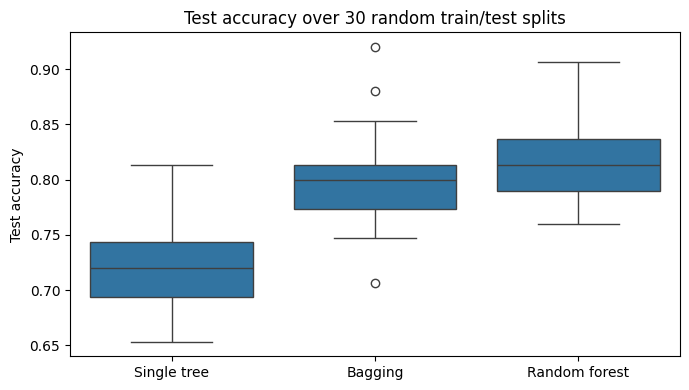

In [8]:
results = []
for seed in range(30):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=seed, stratify=y)
    for name, model in {
        "Single tree":   DecisionTreeClassifier(random_state=seed),
        "Bagging":       RandomForestClassifier(n_estimators=200, max_features=None,
                                                n_jobs=-1, random_state=seed),
        "Random forest": RandomForestClassifier(n_estimators=200, max_features="sqrt",
                                                n_jobs=-1, random_state=seed),
    }.items():
        model.fit(Xtr, ytr)
        results.append({"model": name, "seed": seed, "test_accuracy": model.score(Xte, yte)})

results = pd.DataFrame(results)
print(results.groupby("model")["test_accuracy"].agg(["mean", "std"]).round(3)
      .loc[["Single tree", "Bagging", "Random forest"]])

plt.figure(figsize=(7, 4))
sns.boxplot(data=results, x="model", y="test_accuracy",
            order=["Single tree", "Bagging", "Random forest"])
plt.title("Test accuracy over 30 random train/test splits")
plt.ylabel("Test accuracy")
plt.xlabel("")
plt.tight_layout()
plt.show()

**Interpretation:** the single tree has the lowest average accuracy and the widest spread. Bagging improves it by averaging. The random forest usually does at least as well as bagging.

On a small dataset like this, the gap between bagging and random forest is small. The gap from the single tree to either ensemble is the big one.

## Seeing Problem 2: How Correlated Are the Trees?

The formula says a random forest wins by **lowering the correlation $\rho$** between trees. We can measure it directly. For every pair of trees, we compute the correlation between their predicted probabilities on the test patients, then average over all pairs.

In [9]:
def mean_tree_correlation(forest, X_eval):
    # Each row of P holds one tree's predicted P(disease) for every test patient
    P = np.array([t.predict_proba(X_eval.values)[:, 1] for t in forest.estimators_])
    R = np.corrcoef(P)
    upper = R[np.triu_indices_from(R, k=1)]      # all pairs of different trees
    return np.nanmean(upper)

for name in ["Bagging", "Random forest"]:
    rho = mean_tree_correlation(models[name], X_test)
    print(f"{name:<15} average correlation between trees: {rho:.2f}")

Bagging         average correlation between trees: 0.50
Random forest   average correlation between trees: 0.45


Bagged trees are more correlated because they all have every feature available and keep choosing the same strong splits. Restricting each split to $\sqrt{p}$ features makes the trees more different. This is exactly the $\rho$ in the variance formula.

## Tuning: How Many Trees? How Many Features?

**Number of trees ($B$).** More trees never makes a random forest overfit. The error levels off once there are enough trees, and extra trees only cost computation time. We can watch this with the OOB score, without touching the test set.

/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


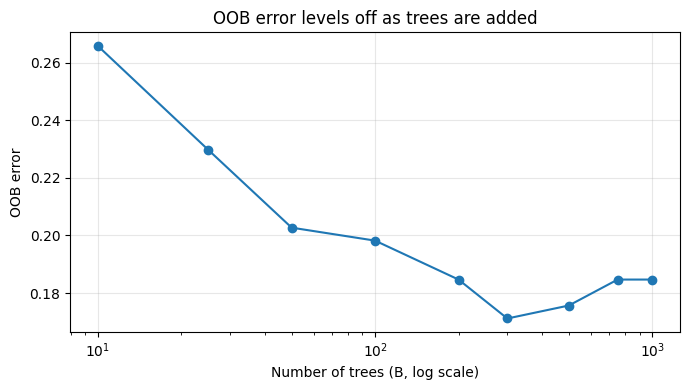

In [11]:
n_trees_list = [10, 25, 50, 100, 200, 300, 500, 750, 1000]
oob_errors = []

for B in n_trees_list:
    rf = RandomForestClassifier(n_estimators=B, max_features="sqrt",
                                oob_score=True, n_jobs=-1, random_state=0)
    rf.fit(X_train, y_train)
    oob_errors.append(1 - rf.oob_score_)

plt.figure(figsize=(7, 4))
plt.plot(n_trees_list, oob_errors, marker="o")
plt.xscale("log")
plt.xlabel("Number of trees (B, log scale)")
plt.ylabel("OOB error")
plt.title("OOB error levels off as trees are added")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

*(With very few trees, some training rows are never out-of-bag, and scikit-learn may print a warning. That is expected.)*

**Features per split ($m$).** This is the main tuning parameter. Small $m$ gives very different (decorrelated) trees, but each tree is weaker. Large $m$ gives strong but similar trees. $m = p = 13$ is bagging.

Because OOB estimates are noisy on a small dataset, we average over 5 random seeds.

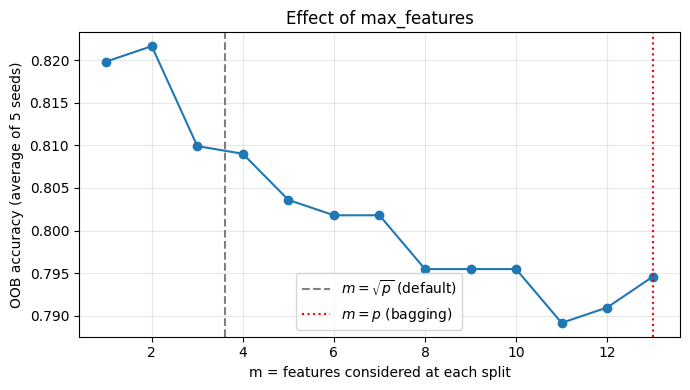

In [12]:
m_values = range(1, X.shape[1] + 1)
oob_by_m = []

for m in m_values:
    scores = []
    for seed in range(5):
        rf = RandomForestClassifier(n_estimators=300, max_features=m,
                                    oob_score=True, n_jobs=-1, random_state=seed)
        rf.fit(X_train, y_train)
        scores.append(rf.oob_score_)
    oob_by_m.append(np.mean(scores))

plt.figure(figsize=(7, 4))
plt.plot(list(m_values), oob_by_m, marker="o")
plt.axvline(np.sqrt(X.shape[1]), color="gray", linestyle="--", label=r"$m=\sqrt{p}$ (default)")
plt.axvline(X.shape[1], color="red", linestyle=":", label="$m=p$ (bagging)")
plt.xlabel("m = features considered at each split")
plt.ylabel("OOB accuracy (average of 5 seeds)")
plt.title("Effect of max_features")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Question for you:** where is the best $m$ on this plot? Is the default $\sqrt{p}$ a reasonable choice?

In practice: start with the default, then try a few values of `max_features` (and maybe `min_samples_leaf`) with the OOB score or cross-validation, as in the cross-validation notebook.

## The Final Model: OOB vs. Test, and the Confusion Matrix

The OOB score is computed only from the training data. If it is a good estimate, it should be close to the test accuracy.

OOB accuracy  (training data only): 0.824
Test accuracy (held-out patients):  0.840

              precision    recall  f1-score   support

  No disease       0.85      0.85      0.85        40
     Disease       0.83      0.83      0.83        35

    accuracy                           0.84        75
   macro avg       0.84      0.84      0.84        75
weighted avg       0.84      0.84      0.84        75



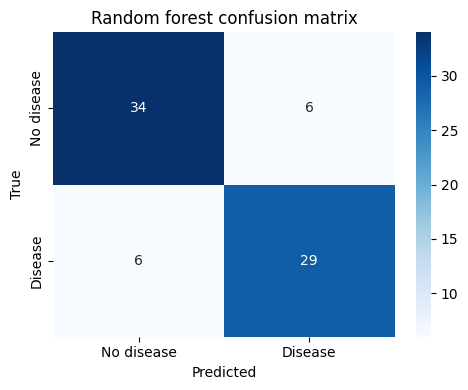

In [13]:
rf = models["Random forest"]
y_pred = rf.predict(X_test)

print(f"OOB accuracy  (training data only): {rf.oob_score_:.3f}")
print(f"Test accuracy (held-out patients):  {accuracy_score(y_test, y_pred):.3f}")
print()
print(classification_report(y_test, y_pred, target_names=["No disease", "Disease"]))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No disease", "Disease"], yticklabels=["No disease", "Disease"])
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Random forest confusion matrix")
plt.tight_layout()
plt.show()

In medicine, the two kinds of mistakes are not equal. Which cell of the confusion matrix would worry a doctor most? (Recall the classification metrics notebook.)

Like any classifier, a random forest also gives probabilities: `rf.predict_proba(X_test)[:, 1]` is the fraction of trees voting "disease". You can lower the 0.5 threshold to catch more sick patients.

## Which Features Matter? Feature Importance

A forest of 500 trees is hard to read, so we lose the simple picture of a single tree. **Feature importance** gives some of it back. There are two common types:

* **Impurity-based importance** (`rf.feature_importances_`): how much each feature decreases Gini impurity, summed over all splits and averaged over all trees. It is free to compute, but it is measured on the training data and tends to favor features with many unique values (continuous features).
* **Permutation importance**: shuffle one feature's column in the **test** set and measure how much accuracy drops. If shuffling a feature hurts a lot, the model relies on it. It is slower but more trustworthy.

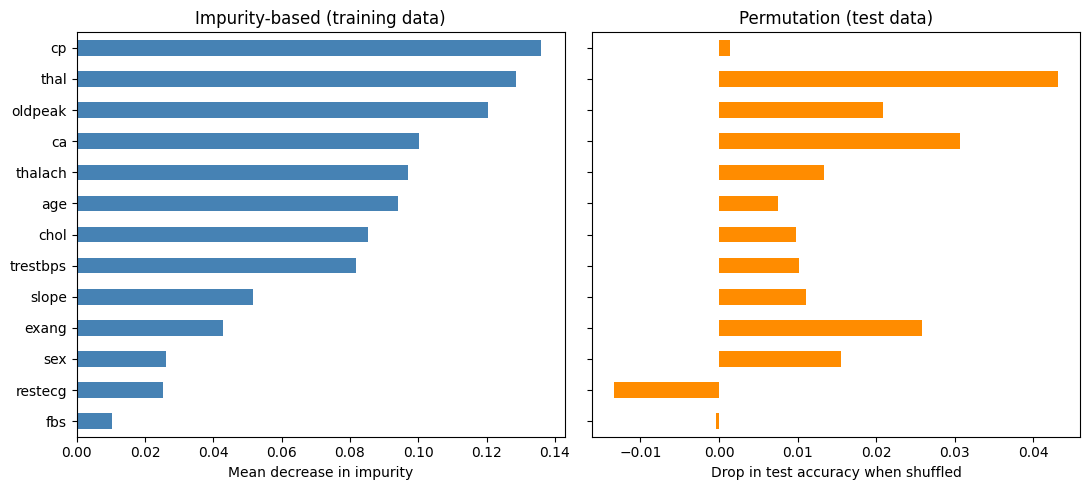

In [14]:
imp_impurity = pd.Series(rf.feature_importances_, index=X.columns)

perm = permutation_importance(rf, X_test, y_test, n_repeats=30, random_state=0, n_jobs=-1)
imp_perm = pd.Series(perm.importances_mean, index=X.columns)

order = imp_impurity.sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
imp_impurity[order].plot.barh(ax=axes[0], color="steelblue")
axes[0].set_title("Impurity-based (training data)")
axes[0].set_xlabel("Mean decrease in impurity")
imp_perm[order].plot.barh(ax=axes[1], color="darkorange")
axes[1].set_title("Permutation (test data)")
axes[1].set_xlabel("Drop in test accuracy when shuffled")
plt.tight_layout()
plt.show()

**Things to notice:**

* Which features rank near the top in both plots? Do they make medical sense?
* Do the two methods disagree anywhere? Continuous features such as `chol` or `age` often look more important in the impurity plot than in the permutation plot.
* A permutation importance near zero (or slightly negative) means the model does not need that feature to predict new patients.

Importance tells you what the **model** uses, not what **causes** heart disease.

## Applications

**As a prediction model.** Random forests work well on tabular data with mixed feature types and need little tuning and no feature scaling.

* **Healthcare:** disease risk from patient records (like our example).
* **Finance:** credit scoring, loan default, fraud detection.
* **Marketing:** customer churn and response to campaigns.
* **Remote sensing and ecology:** land-cover classification from satellite images, species distribution.
* **Genomics:** finding genes linked to a disease when there are thousands of features and few samples.

**As a tool inside the ML pipeline.**

| Use | Idea | Example |
|---|---|---|
| **Feature selection** | Rank features by importance and keep the useful ones | Reduce 80 house features to the ones that drive price |
| **Filling missing values** (missForest) | For a column with gaps, train a forest on the rows where it is known and predict the missing entries | Predict a passenger's missing age from class, fare, family size |
| **Outlier / mislabel detection** | Two rows are "close" if they often land in the same leaf (*proximity*). A row far from its own class is suspicious | Flag possibly mislabeled patients |
| **Anomaly detection** (Isolation Forest) | Random trees isolate unusual points in very few splits | Unusual credit-card transactions |
| **Baseline model** | Strong accuracy with almost no tuning, so it is a good benchmark | "Does my neural net beat a random forest?" |
| **Prediction intervals** (quantile regression forests) | Keep all training values in each leaf, not just their mean | "Price is \$300k–\$360k", not only "\$330k" |
| **Causal effects** (causal forests) | Estimate how a treatment's effect varies across people | Which patients benefit most from a drug |

In the worksheet you will try the first two: **feature selection** on house prices and **filling missing values** on two datasets.

## Key Insights: Random Forest vs. a Single Tree

**Single decision tree**
* Pros: easy to read and explain; fast.
* Cons: high variance; small data changes can change the whole tree.

**Random forest**
* Pros: much lower variance and usually higher accuracy; very little tuning; no scaling needed; free OOB estimate; feature importance.
* Cons: harder to interpret (500 trees instead of one); slower to train and predict; larger to store; cannot predict outside the range of the training targets (in regression).

**Remember:**
* **Bagging** = many trees on bootstrap samples, averaged → reduces variance.
* **Random forest** = bagging + a random subset of $m$ features at each split → also reduces the **correlation** between trees, so averaging works better.
* More trees does not overfit. The main parameter to tune is `max_features` ($m$).

**Next:** boosting (and XGBoost) takes a different approach. Instead of growing deep trees in parallel and averaging them, it grows small trees **one after another**, each fixing the errors of the previous ones.

##In-class Group work

train a RF on housing dataset (Kaggle or Sklearn) and find the important features (e.g.top 10)

In [17]:
# load california_housing dataset from sklearn
from sklearn.datasets import fetch_california_housing
housing = fetch_california_housing()
X = pd.DataFrame(housing.data, columns=housing.feature_names)
y = pd.Series(housing.target)

In [18]:
#train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [25]:
#create an RF object
rf = RandomForestRegressor(n_estimators=100, max_features=0.33, random_state=42)

In [ ]:
#train RF on X_train


In [ ]:
# select top 10 features